# 08 · Registro de experimentos

Cómo se llegó al modelo final, ronda a ronda y en formato compacto. Cada ronda tiene **qué se probó, qué salió y qué se decidió**, con sus tablas.

**Cómo leer los números:** son el error (RMSE en dólares) **relativo al modelo ingenuo** («el precio dentro de *h* días será el de hoy»). **1 es el ingenuo; por debajo de 1 la red lo mejora** (verde) y por encima lo empeora (rojo).
- **Validación:** walk-forward con un bloque por año (2019-2023). Todas las decisiones se toman con ella.
- **Validación hacia atrás:** 2010-2018, años que no se usan para elegir nada; sirve para comprobar si la ventaja de validación se sostiene.
- **Test:** 2024-2026, reservado para el modelo final (notebook 07).
- **red / ajustada:** la predicción de la red tal cual, o multiplicada por un peso entre 0 y 1 elegido en validación, que la acerca al ingenuo cuando la red aporta poco (peso 0 es el ingenuo).

Las tablas se leen de `reports/results/ronda_N/` y `reports/tuning/ronda_N/`.

In [1]:
from IPython.display import display

from oil_forecast import experiment_log as log
from oil_forecast.config import RESULTS_DIR
from oil_forecast.plotting import set_style

set_style()
ROUNDS = sorted(int(p.name.split("_")[1]) for p in RESULTS_DIR.glob("ronda_*") if log.validation(int(p.name.split("_")[1])) is not None)
ROUNDS

[1, 2, 3, 4, 5]

## Resumen

La mejor red de cada ronda en validación, por horizonte.

,1 semana · mejor en validación,1 semana · error,3 meses · mejor en validación,3 meses · error,1 año · mejor en validación,1 año · error
Ronda,,,,,,
1,RNN simple,0.994,RNN simple,0.919,LSTM,0.980
2,RNN simple ajustada,0.995,Combinación ajustada,0.962,LSTM ajustada,0.985
3,RNN simple · lineal ajustada,0.995,RNN simple · top-5,0.901,LSTM · top-5 ajustada,0.979
4,RNN simple · top-5 + lineal ajustada,0.995,RNN simple · top-5 x2 semillas ajustada,0.938,LSTM · top-5 x2 semillas ajustada,0.977
5,RNN simple · top-5 x2 semillas ajustada,0.996,RNN simple · top-3 x2 semillas,0.956,LSTM,0.903


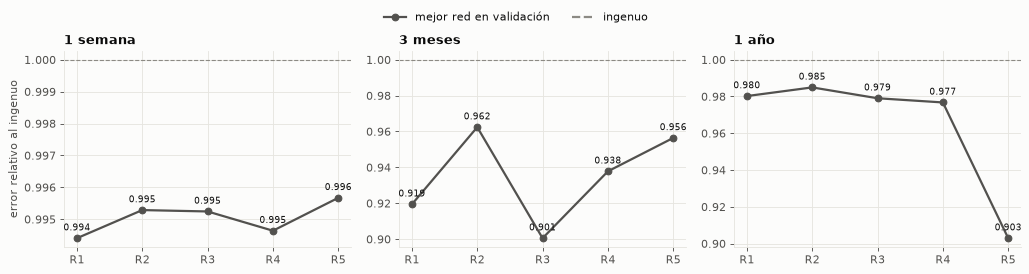

In [2]:
display(log.summary_table(ROUNDS))
log.evolution_plot(ROUNDS);

- **1 semana:** todas las rondas están en ≈ 0,99-1,00. Es prácticamente el ingenuo y no cambia con nada de lo probado.
- **3 meses:** es donde hay señal (0,90-0,97). Las cifras más bajas (rondas 1 y 3) empeoraron al medirlas con más semillas: parte era azar.
- **1 año:** la LSTM es la única red que baja de 1 de forma repetida; en la ronda 5 llega a 0,903.
- La ronda 5 es la que cumple todas las condiciones del enunciado (misma ventana para las tres redes) y la que se lleva al test.

## Ronda 1 · Primera búsqueda

- **Qué:** Optuna con 20 intentos por red y horizonte, ventana fija de 60 días.
- **Resultado:** la validación de esta ronda es la puntuación del propio ajuste, con **una sola semilla por intento**, así que es optimista: la RNN a 3 meses marca 0,919.
- **Decisión:** buscar en un espacio más amplio y medir la validación con 5 semillas, para que la elección dependa menos del azar de la inicialización.

In [3]:
log.validation_table(1)

,1 semana,3 meses,1 año
RNN simple,0.994,0.919,1.157
LSTM,0.997,0.952,0.980
GRU,0.998,0.946,1.095


## Ronda 2 · Búsqueda más amplia, validación con 5 semillas

- **Qué:** 25 intentos por red y horizonte; se prueban ventanas de 20, 60 y 120 días y *learning rates* más bajos. La validación ya se mide con 5 semillas. Aparece la versión **ajustada**.
- **Resultado:** con 5 semillas los números son más realistas: a 3 meses la mejor queda en 0,96-0,97, y a 1 año solo la LSTM ajustada baja de 1.
- **Problema detectado después:** cada red eligió su propia ventana, y el enunciado pide **la misma ventana para las tres**. Las rondas 2 a 4 heredan este fallo; se corrige en la ronda 5.
- **Decisión:** probar mejoras sobre esta búsqueda sin repetirla.

In [4]:
log.validation_table(2)

## Ronda 3 · Ensembles y otras ideas

- **Qué:** tres variantes sobre la búsqueda de la ronda 2:
  - **top-5:** media de las 5 mejores configuraciones;
  - **recientes:** los años recientes pesan más al entrenar;
  - **lineal:** un modelo lineal en paralelo a la red.
- **Resultado:** top-5 da el mayor salto en validación, la RNN a 3 meses en 0,901. *Recientes* empeora casi en todo y se descarta.
- **Decisión:** confirmar la mejora de top-5 con más semillas antes de darla por buena (ronda 4).

In [5]:
log.validation_table(3)

## Ronda 4 · Más semillas, modelo lineal y menos variables

- **Qué:** top-5 con modelo lineal en paralelo, top-5 con el doble de semillas (10 modelos) y top-5 solo con las variables útiles, elegidas por importancia por permutación (desordenar cada variable y ver cuánto empeora el error).
- **Resultado:**
  - **Menos variables empeora en todo:** la RNN a 3 meses pasa a 1,022.
  - **Con el doble de semillas,** la RNN a 3 meses sube de 0,901 a 0,938: parte del 0,901 de la ronda 3 era azar. La cifra realista ronda 0,93-0,94.
  - **top-5 + lineal a 3 meses** es la más estable: ningún año de validación es peor que el ingenuo.
- **Decisión:** rehacer la búsqueda con una ventana común (ronda 5) y llevar las variantes más prometedoras a esa búsqueda.

In [6]:
display(log.importance_table(4), log.validation_table(4))

,1 semana,3 meses,1 año
1,ret_brent (+0.012),vol_21 (+0.057),ratio_cobre_z252 (+0.054)
2,vol_63 (+0.004),basis_wti (+0.017),ret_gas_fut (+0.002)
3,ratio_cobre_z252 (+0.003),vol_63 (+0.016),ratio_oro_z252 (+0.002)
4,tipo_bce_chg_63 (+0.003),tipo_bce_chg_63 (+0.015),ret_brent (+0.001)
5,ret_wti_fut (+0.002),ratio_cobre_z252 (+0.013),ret_oro (+0.001)


### Curvas de aprendizaje (configuraciones de la ronda 4)

Una red de cada tipo y horizonte, entrenada con todo lo anterior a 2024 (`scripts/curvas.py`). La línea discontinua es el error de entrenamiento y la continua, el de validación (el último 15 % del periodo, del que la red no aprende).

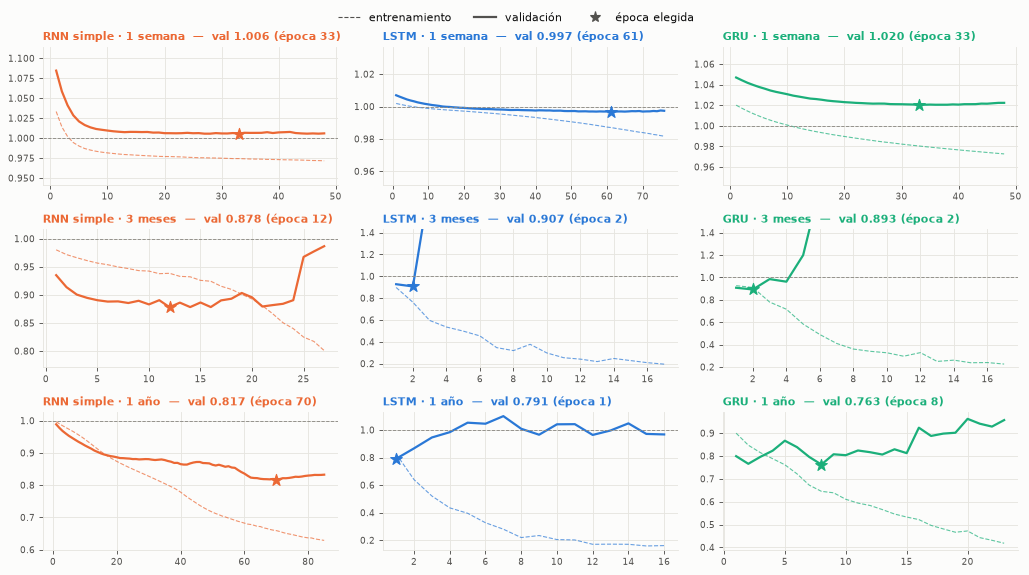

In [7]:
log.curves_grid(4);

- **1 semana:** la validación se queda pegada a 1 en las tres redes. No hay nada que aprender.
- **3 meses:** la **RNN simple** baja hasta una meseta de ≈ 0,88 que dura unas 20 épocas: aprende de verdad. La **LSTM y la GRU** tocan su mejor punto en la época 2 y después memorizan (entrenamiento ≈ 0,2, validación por encima de 2). Les sobra capacidad, y por eso la ronda 5 busca en redes más pequeñas.
- **1 año:** las tres bajan de 1, pero el tramo de validación solo tiene unos 3 cambios anuales independientes y las curvas son muy ruidosas.

## Ronda 5 · Ventana común, nueva búsqueda y modelo final

- **Qué:**
  - **Misma ventana para las tres redes:** búsqueda completa con 20 y con 60 días y regla fijada de antemano para elegir (notebook 06).
  - **Nueva búsqueda:** 30 intentos por red, horizonte y ventana, **2 semillas por intento**, poda de los intentos que van mal y un espacio con redes más pequeñas (16-64 neuronas) y *learning rates* más bajos.
  - **Sin tendencia:** la predicción ya no suma la subida media del periodo de entrenamiento (el auge de 2000-2008 empujaba hacia arriba todas las previsiones a 1 año).
  - **Tres variantes** con las configuraciones de la búsqueda: la mejor con 5 semillas (*base*), las 3 mejores con 2 semillas cada una y las 5 mejores con 2 semillas cada una.
- **Regla de variantes, fijada antes de validar:** por horizonte, con la media de las tres redes, gana la variante con menor error y, a menos de 0,01, la más sencilla; la versión ajustada solo se usa si baja esa media al menos 0,01.

In [8]:
log.window_table(5)

In [9]:
log.variant_table(5)

**Resultado de la regla: *base* en los tres horizontes**, ajustada a 3 meses y a 1 año. Las variantes con más configuraciones no mejoran la media de las tres redes en más de 0,01, así que gana la más sencilla.

Detalle de la validación de la variante elegida, red a red:

In [10]:

v5 = log.validation(5)
v5 = v5[~v5.modelo.str.contains("·") & ~v5.modelo.str.endswith(log.PRUDENT)]
log._style(log._wide(v5, "rmse_relativo"), "Ronda 5 · validación 2019-2023 (variante base)")

**Modelo de la app:** en cada horizonte, la red con menor error en validación, con la versión que diga la regla. Se apuntó en `modelo_final.json` antes de hacer el test.

In [11]:
log.final_model_table(5)

,modelo de la app,peso,validación 2019-2023,años que gana
horizonte,,,,
1 semana,LSTM,1.0,1.000,2 de 5
3 meses,RNN simple ajustada,0.9,0.972,5 de 5
1 año,LSTM ajustada,1.0,0.903,2 de 4


### Curvas de aprendizaje (configuraciones de la ronda 5)

Las mismas curvas que en la ronda 4, ahora con las configuraciones finales (ventana de 20 días).

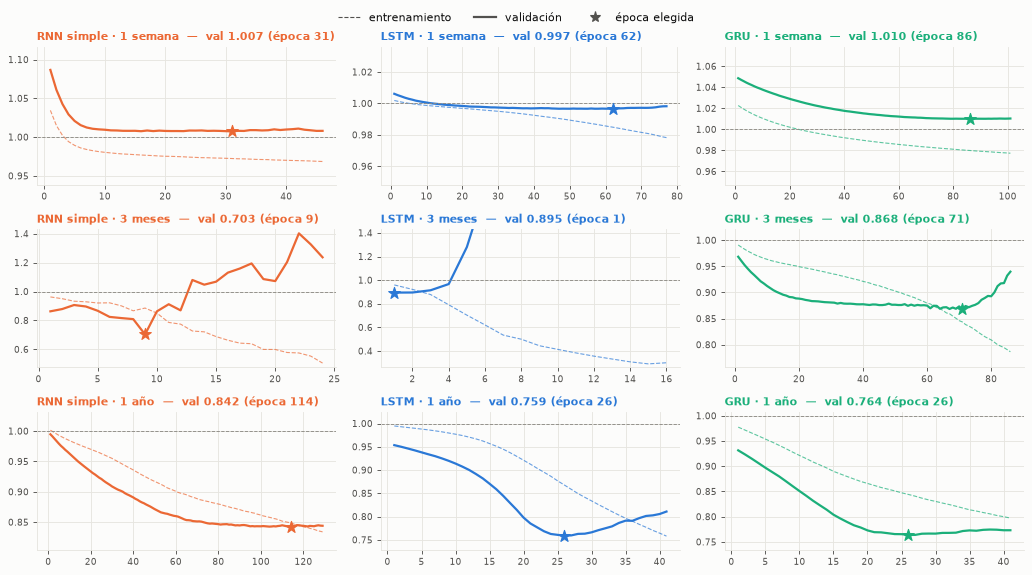

In [12]:
log.curves_grid(5);

- **1 semana:** igual que antes, la validación se queda en ≈ 1,00 en las tres redes.
- **3 meses:** las tres redes **memorizan** si se las deja entrenar: el error de entrenamiento sigue bajando mientras el de validación sube. La **LSTM** tiene su mejor punto en la época 1 (después la validación se dispara por encima de 1,4). La **RNN simple** baja hasta ≈ 0,70 en la época 9 y a partir de ahí empeora deprisa: el resultado depende mucho de en qué época se corte, y eso explica que varíe tanto de una semilla a otra. La **GRU** es la más estable: baja despacio hasta ≈ 0,87 y solo empeora al final.
- **1 año:** las tres bajan de 1 de forma más suave que en la ronda 4. La LSTM y la GRU llegan a ≈ 0,76.

### Validación hacia atrás (2010-2018)

Cinco años de validación son pocos, y todas las decisiones se tomaron con ellos. Para comprobar si la ventaja es real, las configuraciones elegidas se reentrenan **sin cambiar nada** (mismas configuraciones, semillas y pesos) para cada año de 2010 a 2018, solo con los datos anteriores a ese año.

> **Regla fijada antes de ejecutarla:** un modelo **se sostiene** si su error medio con todos los años (2010-2023) es menor que 1 y gana al ingenuo en al menos la mitad; **dudoso** si cumple solo una de las dos; **no se sostiene** si no cumple ninguna. No cambia el modelo final: sirve para saber cuánto fiarse de cada horizonte.

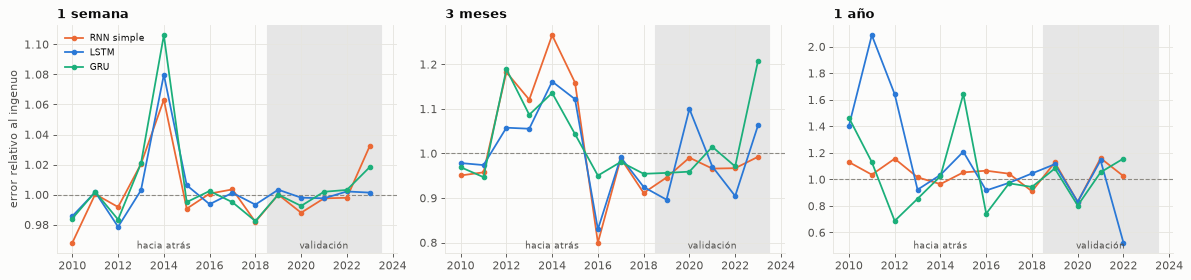

In [13]:
log.backward_plot(5);

In [14]:
log.backward_table(5)

**Lectura:**
- **1 semana:** todo está en ≈ 1,00. Las redes son, en la práctica, el ingenuo.
- **3 meses:** la RNN simple gana al ingenuo en 10 de 14 años, pero 2012-2015 son malos: en 2012-2013 el precio estuvo casi quieto en torno a 110 $, y en 2014-2015 cayó de 110 $ a 35 $ mientras las redes esperaban un rebote. Con todos los años queda en 1,008: **dudoso**.
- **1 año:** la LSTM, la mejor en 2019-2023 (0,903) gracias sobre todo a 2022, falla mucho en 2010-2012. Con todos los años queda en 1,142: **no se sostiene**.
- Las versiones muy ajustadas (pesos pequeños) sí se sostienen, pero porque apenas se separan del ingenuo.

Lo que han aprendido las redes es sobre todo un patrón: **tras una caída fuerte y nerviosa, el precio rebota**. Funciona en 2009, 2016 y 2020 y falla cuando la caída se alarga, como en 2014-2015. La app muestra esta fiabilidad junto a cada previsión.

### Intervalo del 80 %

El enunciado pide un intervalo del 80 % para cada previsión. Se comparan tres métodos sobre las predicciones fuera de muestra de 2010-2023, calibrando cada año **solo con lo ya conocido al empezarlo**:
- **Histórico:** centrado en el precio de hoy, con los percentiles 10 y 90 de las variaciones pasadas a *h* días.
- **Conformal:** centrado en la predicción, con los percentiles 10 y 90 de los errores pasados del modelo.
- **Conformal escalado por volatilidad:** como el anterior, pero los errores se dividen por la volatilidad de 21 días de su momento y se multiplican por la de hoy, así que el intervalo se ensancha cuando el mercado está nervioso.

> **Regla fijada antes de calcular:** entre los métodos con cobertura total entre el 75 % y el 85 %, gana la menor **puntuación de intervalo** (anchura más una penalización cuando el precio cae fuera); uno más sencillo a menos del 2 % gana. Si ninguno cubre lo bastante, el de cobertura más cercana al 80 %.

In [15]:
log.interval_table(5)

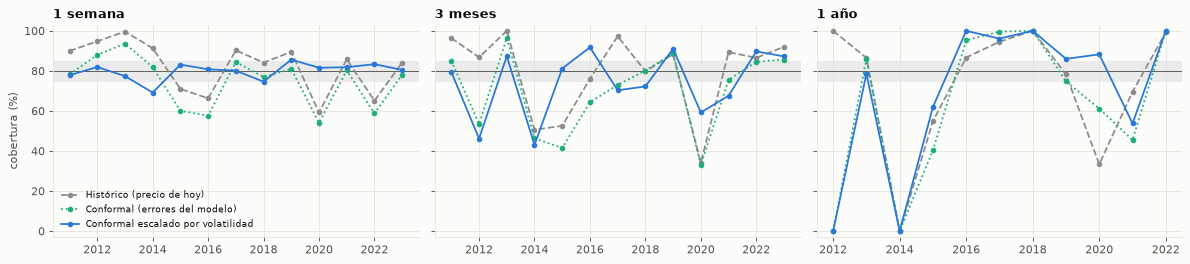

In [16]:
log.interval_plot(5);

**Resultado:**
- **1 semana: conformal escalado por volatilidad** (79,8 %). Es el mejor resultado del trabajo: acierta casi lo mismo en años tranquilos y en crisis (69-86 % por año), mientras que el histórico va del 59 % al 100 %.
- **3 meses: histórico** (78,9 %), el único que cubre lo bastante.
- **1 año: histórico** (72,9 %). Ningún método llega al 75 %; en 2014 el precio cayó un 63 % y ningún intervalo lo cubrió. La app lo presenta como orientativo.

## Lo que se lleva al test

| Horizonte | Modelo | Intervalo del 80 % | Validación hacia atrás |
|---|---|---|---|
| 1 semana | LSTM | conformal escalado por volatilidad | no se sostiene (≈ ingenuo) |
| 3 meses | RNN simple ajustada (peso 0,9) | histórico | dudoso |
| 1 año | LSTM | histórico | no se sostiene |

El notebook 07 evalúa estos modelos, y las tres redes de cada horizonte, en el test 2024-2026.